# 06 · T-Learner (XGBoost) — expected NCM under each action
Four action-specific `XGBRegressor` pipelines learn `E[ncm_14d | X, action]` on **randomized exploration rows only**
(business_rule rows are targeted/confounded). Incremental NCM = predicted NCM(action) − predicted NCM(NO_OFFER).
**Split:** train CP01–05 · validate CP06 (shared config) · test CP07 · final refit CP01–07.

## Load data

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from src.common import TABLES, FIGS, MODELS, load_processed
from src.modeling import ACTIONS, COMMERCIAL, XGB_FIXED, XGB_GRID, feature_lists, make_xgb_pipe, reg_metrics
pd.set_option("display.width", 200)
df = load_processed("historical_feature_outcome")
NUM, CAT = feature_lists()
X_COLS = NUM + CAT
outcomes = set(pd.read_csv(TABLES / "outcome_schema.csv").outcome)
FORBIDDEN = {"assignment_id", "customer_id", "campaign_id", "send_ts", "assignment_source", "offer_type", "email_delivered"} | outcomes
assert len(X_COLS) == 43 and not set(X_COLS) & FORBIDDEN
exp = df[df.assignment_source == "exploration"].copy()
SPLIT = {"train": [f"CP0{i}" for i in range(1, 6)], "valid": ["CP06"], "test": ["CP07"]}
print("exploration rows:", len(exp), "| predictors:", len(X_COLS))
pd.crosstab(exp.campaign_id, exp.offer_type, margins=True)

exploration rows: 7527 | predictors: 43


offer_type,FREE_SHIP,NO_OFFER,PCT_10,PCT_20,All
campaign_id,,,,,
CP01,265,259,271,269,1064
CP02,291,254,262,303,1110
CP03,269,278,256,253,1056
CP04,283,257,288,289,1117
CP05,249,260,246,270,1025
CP06,283,261,285,266,1095
CP07,266,257,294,243,1060
All,1906,1826,1902,1893,7527


## Helpers — fit four action models / factual and counterfactual scoring

In [2]:
def fit_tlearner(d, params):
    return {a: make_xgb_pipe(NUM, CAT, params).fit(d.loc[d.offer_type == a, X_COLS], d.loc[d.offer_type == a, "ncm_14d"]) for a in ACTIONS}

def factual(models, d):
    p = pd.Series(np.nan, index=d.index)
    for a, m in models.items():
        idx = d.offer_type == a
        p[idx] = m.predict(d.loc[idx, X_COLS])
    return p

def counterfactual(models, d):
    out = pd.DataFrame({f"predicted_ncm_{a}": models[a].predict(d[X_COLS]) for a in ACTIONS}, index=d.index)
    for a in ACTIONS:
        out[f"incremental_ncm_{a}"] = out[f"predicted_ncm_{a}"] - out["predicted_ncm_NO_OFFER"]
    out["recommended_action_unconstrained"] = out[[f"predicted_ncm_{a}" for a in ACTIONS]].idxmax(axis=1).str.replace("predicted_ncm_", "")
    return out

tr, va, te = (exp[exp.campaign_id.isin(SPLIT[k])] for k in ("train", "valid", "test"))

## Tune one shared configuration on CP06 (pooled factual RMSE, MAE tie-break)

In [3]:
grid = []
for params in XGB_GRID:
    grid.append({**params, **reg_metrics(va.ncm_14d, factual(fit_tlearner(tr, params), va))})
mean_base = va.offer_type.map(tr.groupby("offer_type").ncm_14d.mean())
grid.append({"n_estimators": "action-mean baseline", **reg_metrics(va.ncm_14d, mean_base)})
grid = pd.DataFrame(grid)
grid.to_csv(TABLES / "tlearner_validation_grid.csv", index=False)
best = grid[grid.n_estimators != "action-mean baseline"].sort_values(["rmse", "mae"]).iloc[0]
BEST = {"n_estimators": int(best.n_estimators), "max_depth": int(best.max_depth), "learning_rate": float(best.learning_rate)}
print("selected:", BEST)
grid[["n_estimators", "max_depth", "learning_rate", "rmse", "mae", "r2"]].round(4)

selected: {'n_estimators': 100, 'max_depth': 1, 'learning_rate': 0.03}


,n_estimators,max_depth,learning_rate,rmse,mae,r2
0,200,2.0,0.03,65.8941,29.6793,0.0001
1,200,2.0,0.05,66.2614,29.7437,-0.0111
2,200,3.0,0.03,66.3181,29.5112,-0.0128
3,200,3.0,0.05,66.8965,29.9346,-0.0305
4,400,2.0,0.03,66.3214,29.8977,-0.0129
5,400,2.0,0.05,67.1459,30.5379,-0.0382
6,400,3.0,0.03,67.0238,30.1709,-0.0345
7,400,3.0,0.05,68.1041,31.4824,-0.0681
8,100,1.0,0.03,65.4905,28.8871,0.0123
9,200,1.0,0.03,65.5184,29.5118,0.0115


## Refit on CP01–06, evaluate once on CP07 (factual accuracy only — individual counterfactuals are never observed)

In [4]:
m_test = fit_tlearner(pd.concat([tr, va]), BEST)
te = te.assign(pred_factual=factual(m_test, te))
rows = [{"scope": "pooled", **reg_metrics(te.ncm_14d, te.pred_factual)}]
rows += [{"scope": a, **reg_metrics(g.ncm_14d, g.pred_factual)} for a, g in te.groupby("offer_type")]
rows.append({"scope": "pooled action-mean baseline", **reg_metrics(te.ncm_14d, te.offer_type.map(pd.concat([tr, va]).groupby("offer_type").ncm_14d.mean()))})
test_metrics = pd.DataFrame(rows)
test_metrics.to_csv(TABLES / "tlearner_test_metrics.csv", index=False)
test_metrics.round(3)

,scope,n,rmse,mae,r2,obs_mean,pred_mean
0,pooled,1060,63.377,27.411,0.006,15.315,16.572
1,FREE_SHIP,266,83.685,39.697,0.004,22.882,23.680
2,NO_OFFER,257,40.965,23.396,-0.039,10.245,17.798
3,PCT_10,294,74.579,27.136,-0.005,16.186,14.796
4,PCT_20,243,36.760,18.541,0.042,11.340,9.642
5,pooled action-mean baseline,1060,63.489,27.162,0.002,15.315,15.399


## Counterfactual scoring of CP07 + comparison with randomized Step 04 effects

In [5]:
cf = counterfactual(m_test, te)
pred = pd.concat([te[["assignment_id", "customer_id", "campaign_id", "offer_type", "ncm_14d"]], cf], axis=1)
pred.to_csv(TABLES / "tlearner_test_predictions.csv", index=False)
step04 = pd.read_csv(TABLES / "incremental_ncm_exploration.csv").query("segment == 'exploration' and outcome == 'ncm_14d'").set_index("offer_type")
cp07_obs = te.groupby("offer_type").ncm_14d.mean()
eff = pd.DataFrame({"model_mean_incremental_ncm_CP07": [cf[f"incremental_ncm_{a}"].mean() for a in ACTIONS],
                    "observed_diff_in_means_CP07": [cp07_obs[a] - cp07_obs["NO_OFFER"] for a in ACTIONS],
                    "step04_randomized_effect_CP01_07": [0.0] + [step04.loc[a, "incremental_ncm"] for a in COMMERCIAL],
                    "step04_ci_low": [0.0] + [step04.loc[a, "ci_low"] for a in COMMERCIAL],
                    "step04_ci_high": [0.0] + [step04.loc[a, "ci_high"] for a in COMMERCIAL],
                    "unconstrained_best_share": [(cf.recommended_action_unconstrained == a).mean() for a in ACTIONS]}, index=ACTIONS)
eff.round(3)

,model_mean_incremental_ncm_CP07,observed_diff_in_means_CP07,step04_randomized_effect_CP01_07,step04_ci_low,step04_ci_high,unconstrained_best_share
NO_OFFER,0.000,0.000,0.000,0.000,0.000,0.128
PCT_10,-1.943,5.941,-1.077,-5.118,2.964,0.088
PCT_20,-7.888,1.095,-6.174,-9.650,-2.699,0.003
FREE_SHIP,6.695,12.637,3.560,-0.887,8.006,0.781


In [6]:
sign_flip = [a for a in COMMERCIAL if np.sign(eff.loc[a, "model_mean_incremental_ncm_CP07"]) != np.sign(eff.loc[a, "step04_randomized_effect_CP01_07"])
             and not (eff.loc[a, "step04_ci_low"] <= eff.loc[a, "model_mean_incremental_ncm_CP07"] <= eff.loc[a, "step04_ci_high"])]
print("sign reversals outside the Step 04 95% CI:", sign_flip or "none")

sign reversals outside the Step 04 95% CI: none


## Held-out policy value (normalized IPW / Hajek) on randomized CP07
Policy = argmax predicted NCM. Propensities = CP07 exploration action frequencies. Bootstrap 95% CI (1,000 draws, seed 42).

In [7]:
prop = te.offer_type.value_counts(normalize=True)
def hajek(policy, d=te):
    w = (d.offer_type.values == policy) / d.offer_type.map(prop).values
    return (w * d.ncm_14d.values).sum() / w.sum()
pol = cf.recommended_action_unconstrained.values
fixed = {a: np.full(len(te), a) for a in ACTIONS}
rng = np.random.default_rng(42)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(te), len(te))
    d = te.iloc[i]
    boot.append(hajek(pol[i], d) - hajek(fixed["NO_OFFER"][i], d))
pv = pd.DataFrame({"policy": ["TLEARNER_ARGMAX"] + [f"ALL_{a}" for a in ACTIONS],
                   "est_ncm_per_customer": [hajek(pol)] + [hajek(fixed[a]) for a in ACTIONS]})
pv["vs_all_no_offer"] = pv.est_ncm_per_customer - hajek(fixed["NO_OFFER"])
pv.loc[0, ["ci_low", "ci_high"]] = np.percentile(boot, [2.5, 97.5])
pv["matched_rows"] = [int((te.offer_type.values == pol).sum())] + [int((te.offer_type == a).sum()) for a in ACTIONS]
pv.to_csv(TABLES / "tlearner_policy_value_cp07.csv", index=False)
pv.round(3)

,policy,est_ncm_per_customer,vs_all_no_offer,ci_low,ci_high,matched_rows
0,TLEARNER_ARGMAX,18.976,8.731,-1.422,20.232,258
1,ALL_NO_OFFER,10.245,0.000,NaN,NaN,257
2,ALL_PCT_10,16.186,5.941,NaN,NaN,294
3,ALL_PCT_20,11.340,1.095,NaN,NaN,243
4,ALL_FREE_SHIP,22.882,12.637,NaN,NaN,266


## Final refit on all CP01–07 exploration rows, save, reload check

In [8]:
final = fit_tlearner(exp, BEST)
for a, m in final.items():
    joblib.dump(m, MODELS / f"tlearner_ncm_{a}.joblib")
reloaded = {a: joblib.load(MODELS / f"tlearner_ncm_{a}.joblib") for a in ACTIONS}
chk = counterfactual(reloaded, exp)
assert np.isfinite(chk.filter(like="predicted_ncm_").values).all()
eff_summary = eff.assign(final_model_mean_incremental_ncm_all_exploration=[chk[f"incremental_ncm_{a}"].mean() for a in ACTIONS])
eff_summary.rename_axis("action").to_csv(TABLES / "tlearner_action_effect_summary.csv")
meta = {"target": "ncm_14d", "training_population": "assignment_source == exploration", "actions": ACTIONS,
        "numeric_features": NUM, "categorical_features": CAT, "xgb_fixed": XGB_FIXED, "xgb_selected": BEST,
        "selection": "min pooled factual RMSE on CP06 (MAE tie-break)", "final_train_rows": {a: int((exp.offer_type == a).sum()) for a in ACTIONS},
        "cp07_pooled": test_metrics.iloc[0][["rmse", "mae", "r2"]].round(4).to_dict()}
(MODELS / "tlearner_metadata.json").write_text(json.dumps(meta, indent=1))
print("saved + reloaded:", [f"tlearner_ncm_{a}.joblib" for a in ACTIONS])

saved + reloaded: ['tlearner_ncm_NO_OFFER.joblib', 'tlearner_ncm_PCT_10.joblib', 'tlearner_ncm_PCT_20.joblib', 'tlearner_ncm_FREE_SHIP.joblib']


## Feature importance (gain, final models; descriptive, not causal)

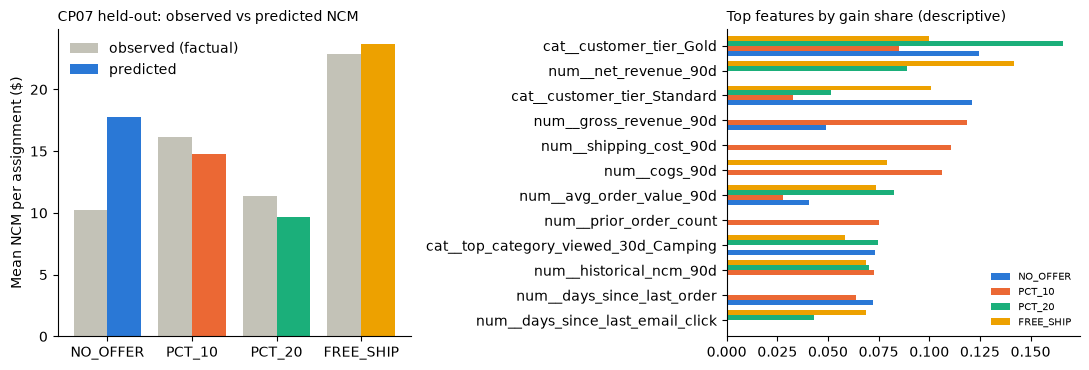

In [9]:
imp = pd.concat({a: pd.Series(m[-1].get_booster().get_score(importance_type="gain")).rename(
    lambda k: m[0].get_feature_names_out()[int(k[1:])] if k.startswith("f") and k[1:].isdigit() else k) for a, m in final.items()}, axis=1).fillna(0)
imp = (imp / imp.sum()).sort_values("NO_OFFER", ascending=False)
imp.rename_axis("encoded_feature").to_csv(TABLES / "tlearner_feature_importance.csv")
top = imp.loc[imp.max(axis=1).sort_values(ascending=False).index[:12]]
COLORS = dict(zip(ACTIONS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(ACTIONS))
ax[0].bar(x - 0.2, [te[te.offer_type == a].ncm_14d.mean() for a in ACTIONS], 0.4, color="#c3c2b7", label="observed (factual)")
ax[0].bar(x + 0.2, [te[te.offer_type == a].pred_factual.mean() for a in ACTIONS], 0.4, color=[COLORS[a] for a in ACTIONS], label="predicted")
ax[0].set_xticks(x, ACTIONS); ax[0].set_ylabel("Mean NCM per assignment ($)"); ax[0].legend(frameon=False)
ax[0].set_title("CP07 held-out: observed vs predicted NCM", loc="left", fontsize=10)
top[::-1].plot.barh(ax=ax[1], color=[COLORS[a] for a in ACTIONS], width=0.8)
ax[1].set_title("Top features by gain share (descriptive)", loc="left", fontsize=10); ax[1].legend(frameon=False, fontsize=7)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIGS / "06_tlearner_diagnostics.png", dpi=110, bbox_inches="tight"); plt.show()